In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_excel("Copy_of_loan.xlsx")

In [7]:
df.shape

(614, 13)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [9]:
print(df.head(5))

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [10]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
print(df["Gender"].unique())
print(df["Married"].unique())
print(df["Dependents"].unique())
print(df["Education"].unique())
print(df["Self_Employed"].unique())
print(df["Property_Area"].unique())
print(df["Loan_Status"].unique())
print(df["Credit_History"].unique())

['Male' 'Female' nan]
['No' 'Yes' nan]
[0 1 2 '3+' nan]
['Graduate' 'Not Graduate']
['No' 'Yes' nan]
['Urban' 'Rural' 'Semiurban']
['Y' 'N']
[ 1.  0. nan]


In [13]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [14]:
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())

In [15]:
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median())

In [16]:
df["Credit_History"] = df["Credit_History"].fillna(df["Credit_History"].mode()[0])

In [17]:
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

In [18]:
df["Self_Employed"] = df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])

In [19]:
df["Married"] = df["Married"].fillna(df["Married"].mode()[0])

In [20]:
df.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents           15
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [21]:
df["Dependents"].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [22]:
df["Dependents"] = df["Dependents"].fillna(df["Dependents"].mode()[0])


In [23]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [24]:
print(df["Gender"].unique())
print(df["Married"].unique())
print(df["Dependents"].unique())
print(df["Education"].unique())
print(df["Self_Employed"].unique())
print(df["Property_Area"].unique())
print(df["Loan_Status"].unique())
print(df["Credit_History"].unique())

['Male' 'Female']
['No' 'Yes']
[0 1 2 '3+']
['Graduate' 'Not Graduate']
['No' 'Yes']
['Urban' 'Rural' 'Semiurban']
['Y' 'N']
[1. 0.]


In [25]:
df["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

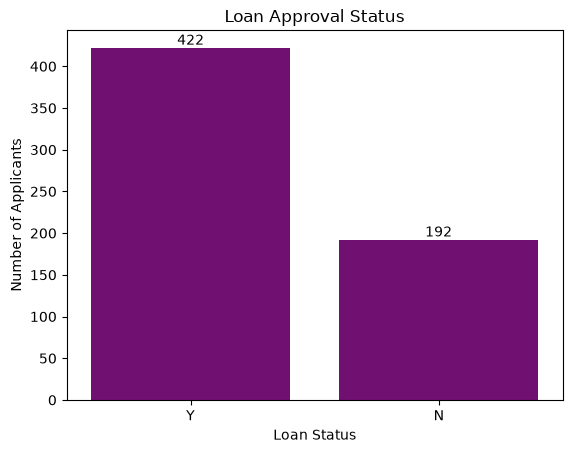

In [26]:
ax =sns.countplot(x="Loan_Status", data=df , color="purple")
ax.bar_label(ax.containers[0])

plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

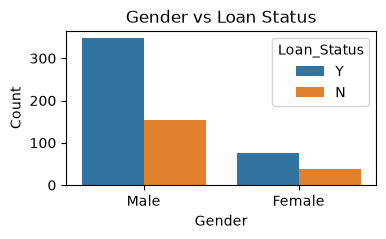

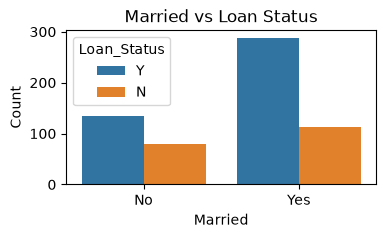

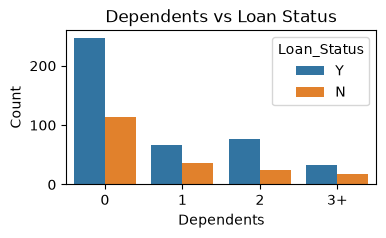

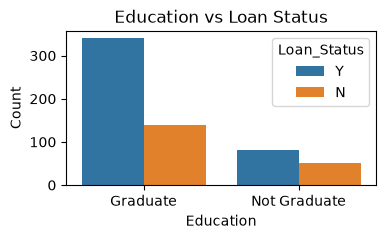

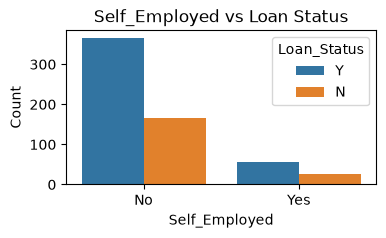

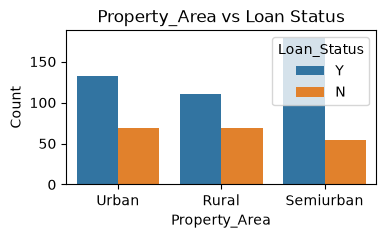

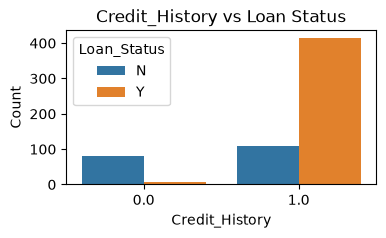

In [27]:
categorical_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area",
    "Credit_History"
]

for col in categorical_cols:
    plt.figure(figsize=(4,2))
    
    ax = sns.countplot(x=col, hue="Loan_Status", data=df)
    
    plt.title(f"{col} vs Loan Status")
    plt.xlabel(col)
    plt.ylabel("Count")
    
    plt.show()

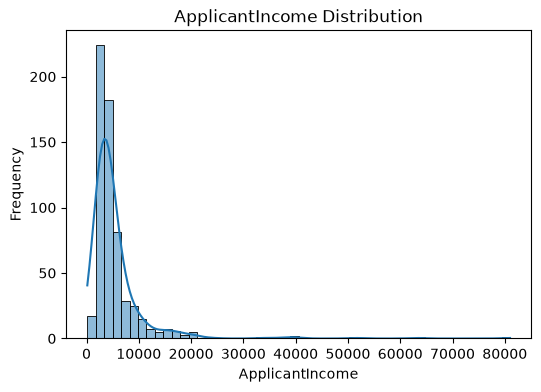

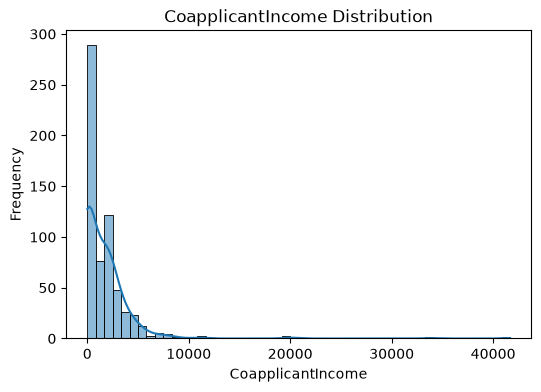

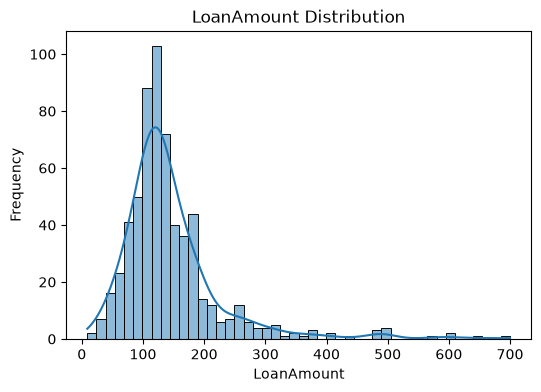

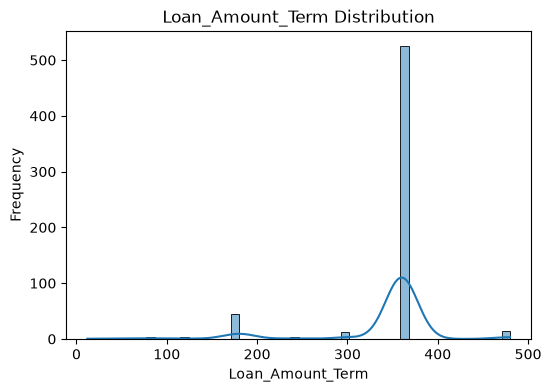

In [28]:
numerical_cols = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

for col in numerical_cols:
    plt.figure(figsize=(6,4))
    
    sns.histplot(df[col], kde=True)
    
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.show()

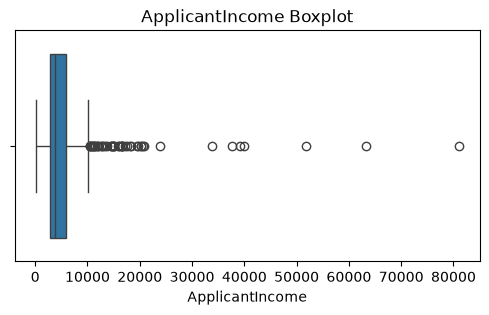

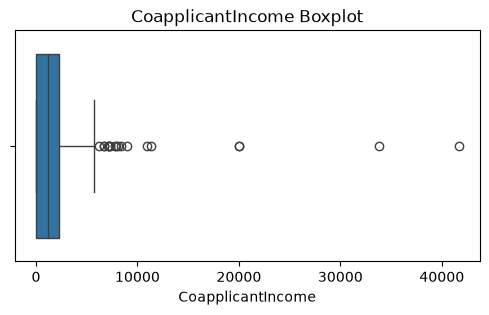

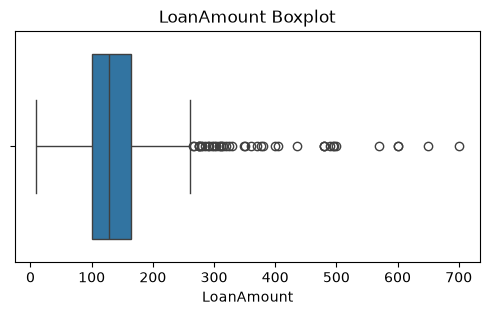

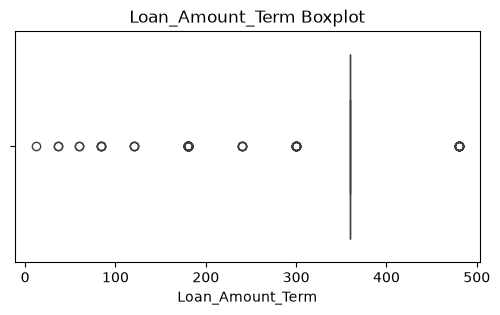

In [29]:
for col in numerical_cols:
    plt.figure(figsize=(6,3))
    
    sns.boxplot(x=df[col])
    
    plt.title(f"{col} Boxplot")
    
    plt.show()

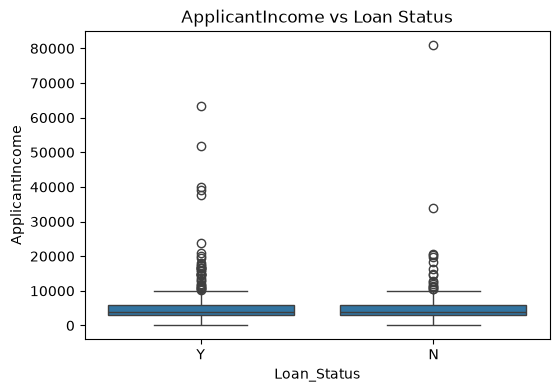

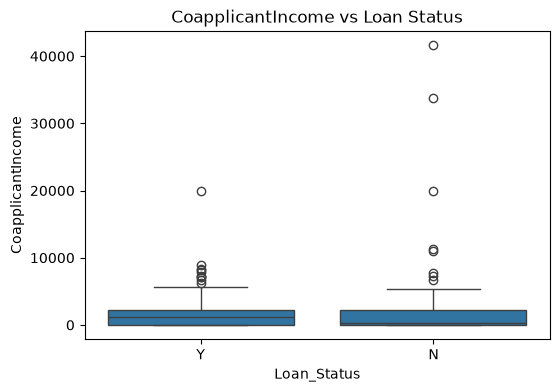

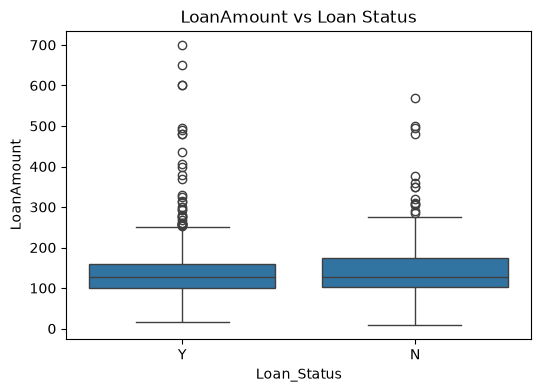

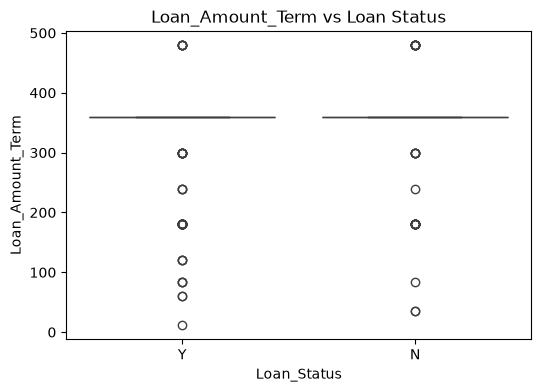

In [30]:
for col in numerical_cols:
    plt.figure(figsize=(6,4))
    
    sns.boxplot(x="Loan_Status", y=col, data=df)
    
    plt.title(f"{col} vs Loan Status")
    
    plt.show()

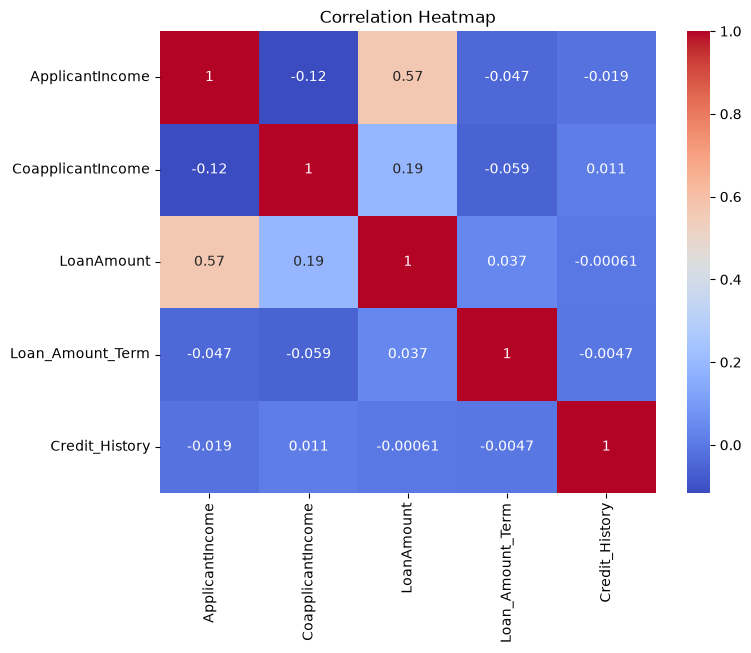

In [31]:
plt.figure(figsize=(8,6))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [32]:
pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Credit_History,,
0.0,92.134831,7.865169
1.0,20.952381,79.047619


In [33]:
df = df.drop("Loan_ID", axis=1)

In [34]:
df["Dependents"] = df["Dependents"].replace("3+", "3")
df["Dependents"] = df["Dependents"].astype(int)

In [35]:
df["Dependents"].unique()

array([0, 1, 2, 3])

In [36]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])
df["Married"] = le.fit_transform(df["Married"])
df["Self_Employed"] = le.fit_transform(df["Self_Employed"])
df["Loan_Status"] = le.fit_transform(df["Loan_Status"])

In [37]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(
    categories=[["Not Graduate", "Graduate"]]
)

df[["Education"]] = oe.fit_transform(df[["Education"]])

In [38]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder(
    categories=[["0", "1", "2", "3"]]
)

df[["Dependents"]] = oe.fit_transform(df[["Dependents"]])

In [39]:
df["Dependents"].unique()

array([0., 1., 2., 3.])

In [40]:
df = pd.get_dummies(
    df,
    columns=["Property_Area"],
    drop_first=True
)

In [41]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Loan_Status',
       'Property_Area_Semiurban', 'Property_Area_Urban'],
      dtype='object')

In [42]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    float64
 3   Education                614 non-null    float64
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    int64  
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    float64
 10  Loan_Status              614 non-null    int64  
 11  Property_Area_Semiurban  614 non-null    bool   
 12  Property_Area_Urban      614 non-null    bool   
dtypes: bool(2), float64(6), int64(5)
memory usage: 54.1 KB


In [43]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [45]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [46]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

from sklearn.metrics import accuracy_score
svm_accuracy = accuracy_score(Y_test, y_pred_svm)
print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7967479674796748


In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, Y_train)
y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(Y_test, y_pred_rf)
print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7560975609756098


In [48]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [49]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, Y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(Y_test, y_pred_xgb)
print("XGBoost Accuracy:", xgb_accuracy)


XGBoost Accuracy: 0.7560975609756098


In [50]:
from sklearn.metrics import classification_report

print("SVM Classification Report:")
print(classification_report(Y_test, y_pred_svm))



SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.42      0.59        43
           1       0.76      1.00      0.86        80

    accuracy                           0.80       123
   macro avg       0.88      0.71      0.73       123
weighted avg       0.85      0.80      0.77       123



In [51]:
print("Random Forest Classification Report:")
print(classification_report(Y_test, y_pred_rf))



Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.42      0.55        43
           1       0.75      0.94      0.83        80

    accuracy                           0.76       123
   macro avg       0.77      0.68      0.69       123
weighted avg       0.76      0.76      0.73       123



In [52]:
print("XGBoost Classification Report:")
print(classification_report(Y_test, y_pred_xgb))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.51      0.59        43
           1       0.77      0.89      0.83        80

    accuracy                           0.76       123
   macro avg       0.74      0.70      0.71       123
weighted avg       0.75      0.76      0.74       123



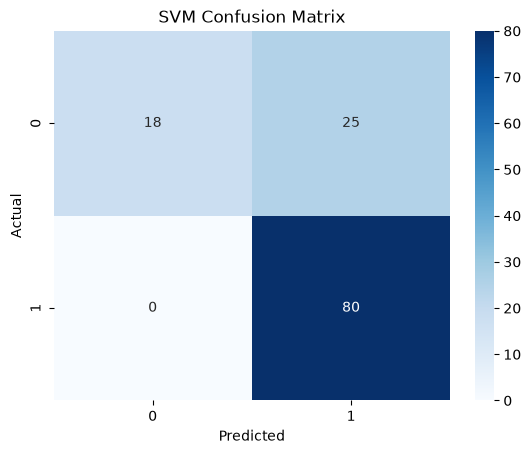

In [53]:
from sklearn.metrics import confusion_matrix
cm_svm = confusion_matrix(Y_test, y_pred_svm)

sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

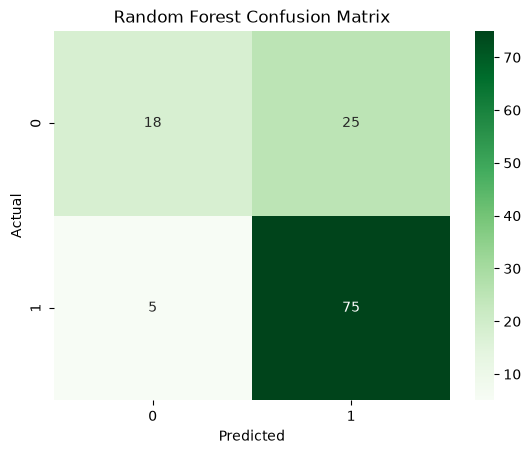

In [54]:
cm_rf = confusion_matrix(Y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

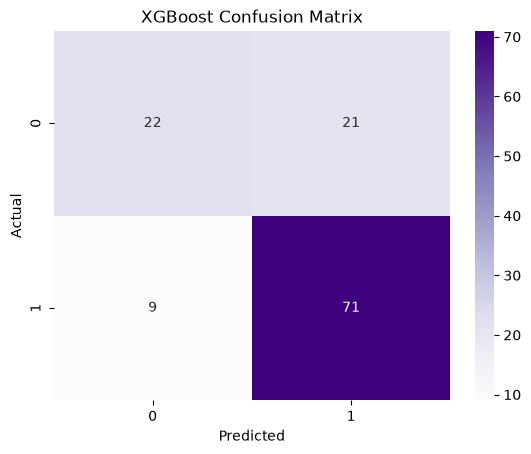

In [55]:
cm_xgb = confusion_matrix(Y_test, y_pred_xgb)

sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Purples")

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [56]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=12,
    eval_metric="logloss"
)

xgb_model.fit(X_train, Y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(Y_test, y_pred_xgb)
print("XGBoost Accuracy:", xgb_accuracy)


XGBoost Accuracy: 0.7560975609756098


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    float64
 3   Education                614 non-null    float64
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    int64  
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    float64
 10  Loan_Status              614 non-null    int64  
 11  Property_Area_Semiurban  614 non-null    bool   
 12  Property_Area_Urban      614 non-null    bool   
dtypes: bool(2), float64(6), int64(5)
memory usage: 54.1 KB


In [58]:
df.drop(columns=["Education"])

,Gender,Married,Dependents,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0.0,0,5849,0.0,128.0,360.0,1.0,1,False,True
1,1,1,1.0,0,4583,1508.0,128.0,360.0,1.0,0,False,False
2,1,1,0.0,1,3000,0.0,66.0,360.0,1.0,1,False,True
3,1,1,0.0,0,2583,2358.0,120.0,360.0,1.0,1,False,True
4,1,0,0.0,0,6000,0.0,141.0,360.0,1.0,1,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0.0,0,2900,0.0,71.0,360.0,1.0,1,False,False
610,1,1,3.0,0,4106,0.0,40.0,180.0,1.0,1,False,False
611,1,1,1.0,0,8072,240.0,253.0,360.0,1.0,1,False,True
612,1,1,2.0,0,7583,0.0,187.0,360.0,1.0,1,False,True


In [59]:
from sklearn.preprocessing import LabelEncoder

la = LabelEncoder()
df["Education"] = la.fit_transform(df["Education"])

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    float64
 3   Education                614 non-null    int64  
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    int64  
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    float64
 10  Loan_Status              614 non-null    int64  
 11  Property_Area_Semiurban  614 non-null    bool   
 12  Property_Area_Urban      614 non-null    bool   
dtypes: bool(2), float64(5), int64(6)
memory usage: 54.1 KB


In [61]:
df=df.drop(columns=["Married"])

In [62]:
df["ApplicantIncome"].eq(0).sum()

np.int64(0)

In [63]:
df[df["ApplicantIncome"] == 0]

,Gender,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban


In [64]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

from sklearn.metrics import accuracy_score
svm_accuracy = accuracy_score(Y_test, y_pred_svm)
print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7967479674796748


In [65]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

In [66]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [67]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [68]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

from sklearn.metrics import accuracy_score
svm_accuracy = accuracy_score(Y_test, y_pred_svm)
print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7886178861788617


In [69]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



In [70]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(Y_test, y_pred_svm)
print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7886178861788617


In [71]:
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

In [72]:
df["EMI"] = df["LoanAmount"] / df["Loan_Amount_Term"]

In [73]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [74]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
from sklearn.metrics import accuracy_score, classification_report

svm_accuracy = accuracy_score(Y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)
print(classification_report(Y_test, y_pred_svm))

SVM Accuracy: 0.7967479674796748
              precision    recall  f1-score   support

           0       1.00      0.42      0.59        43
           1       0.76      1.00      0.86        80

    accuracy                           0.80       123
   macro avg       0.88      0.71      0.73       123
weighted avg       0.85      0.80      0.77       123



In [75]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train_scaled, Y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
from sklearn.metrics import accuracy_score, classification_report

svm_accuracy = accuracy_score(Y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)


SVM Accuracy: 0.7967479674796748


In [76]:
print(df.corr()["Loan_Status"].sort_values(ascending=False))

Loan_Status                1.000000
Credit_History             0.540556
Property_Area_Semiurban    0.136540
Education                  0.085884
Gender                     0.017987
Dependents                 0.010118
Self_Employed             -0.003700
ApplicantIncome           -0.004710
EMI                       -0.011757
Loan_Amount_Term          -0.022549
TotalIncome               -0.031271
LoanAmount                -0.033214
Property_Area_Urban       -0.043621
CoapplicantIncome         -0.059187
Name: Loan_Status, dtype: float64


In [77]:
print(df["Loan_Status"].value_counts())

Loan_Status
1    422
0    192
Name: count, dtype: int64


In [78]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [79]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC()

svm_model.fit(X_train_scaled, Y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(Y_test, y_pred_svm))


SVM Accuracy: 0.8455284552845529


In [80]:
df["LoanIncomeRatio"] = df["LoanAmount"] / (df["TotalIncome"] + 1)

In [81]:
df["CreditIncome"] = df["Credit_History"] * df["TotalIncome"]

In [82]:
df = df.drop(columns=["EMI"])

In [83]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC()

svm_model.fit(X_train_scaled, Y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(Y_test, y_pred_svm))

SVM Accuracy: 0.8373983739837398


In [84]:
df.drop(columns=["LoanIncomeRatio", "CreditIncome"], inplace=True)

In [99]:
X = df.drop("Loan_Status", axis=1)
Y = df["Loan_Status"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC()

svm_model.fit(X_train_scaled, Y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(Y_test, y_pred_svm))

SVM Accuracy: 0.8536585365853658


In [86]:
print(classification_report(Y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



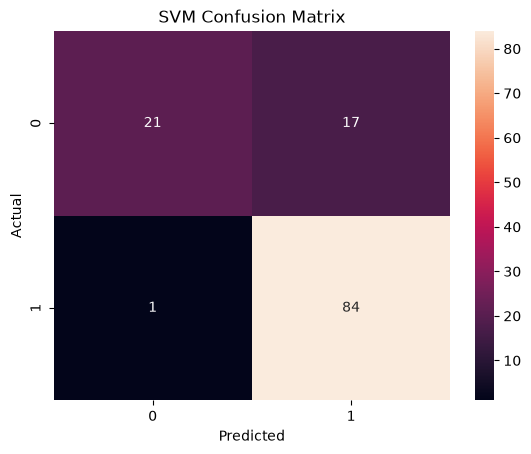

In [87]:
cm = confusion_matrix(Y_test, y_pred_svm)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

In [111]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, Y_train)
y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(Y_test, y_pred_rf)
print("Random Forest Accuracy:", rf_accuracy)
print(classification_report(Y_test, y_pred_rf))

Random Forest Accuracy: 0.8536585365853658
              precision    recall  f1-score   support

           0       0.78      0.74      0.76        38
           1       0.89      0.91      0.90        85

    accuracy                           0.85       123
   macro avg       0.83      0.82      0.83       123
weighted avg       0.85      0.85      0.85       123



In [89]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, Y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(Y_test, y_pred_xgb)
print("XGBoost Accuracy:", xgb_accuracy)


XGBoost Accuracy: 0.8292682926829268


In [90]:
print(df.columns)

Index(['Gender', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome',
       'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status', 'Property_Area_Semiurban', 'Property_Area_Urban',
       'TotalIncome'],
      dtype='object')


In [91]:
import pickle
pickle.dump(svm_model, open("svm_model.pkl", "wb"))
pickle.dump(rf_model, open("rf_model.pkl", "wb"))
pickle.dump(xgb_model,open("xgb_model.pkl", "wb"))

In [92]:
pickle.dump(scaler, open("scaler.pkl", "wb"))

In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Dependents               614 non-null    float64
 2   Education                614 non-null    int64  
 3   Self_Employed            614 non-null    int64  
 4   ApplicantIncome          614 non-null    int64  
 5   CoapplicantIncome        614 non-null    float64
 6   LoanAmount               614 non-null    float64
 7   Loan_Amount_Term         614 non-null    float64
 8   Credit_History           614 non-null    float64
 9   Loan_Status              614 non-null    int64  
 10  Property_Area_Semiurban  614 non-null    bool   
 11  Property_Area_Urban      614 non-null    bool   
 12  TotalIncome              614 non-null    float64
dtypes: bool(2), float64(6), int64(5)
memory usage: 54.1 KB


In [94]:
from mlxtend.plotting import plot_decision_regions

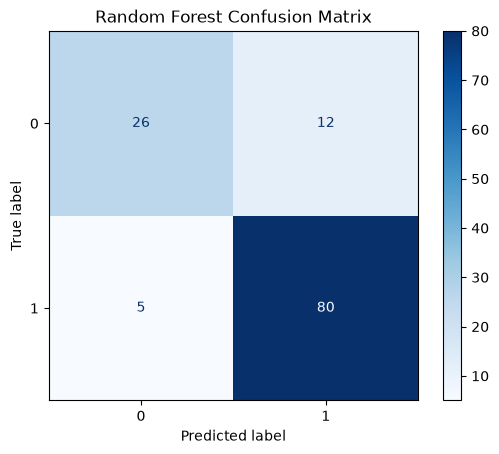

In [97]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title("Random Forest Confusion Matrix")
plt.show()